# Time Series Breakdown of Retail Sales
### Walmart Store Sales — trend, moving averages, seasonality, product × region breakdown, and forecasting

**Objective.** Analyse Walmart's weekly store sales as a time series: measure the trend, smooth it with moving averages, isolate seasonal patterns, break revenue down by product (department) and region over time, and finish with a simple forecast (rolling mean and exponential smoothing).

**Dataset.** *Walmart Recruiting – Store Sales Forecasting* (Kaggle): 45 stores × 81 departments, weekly sales from 2010-02-05 to 2012-10-26 (143 weeks, ~421k rows).

| Business term in the brief | Column used in this dataset |
|---|---|
| Product | `Dept` (department number) |
| Region | `Type` (store format A/B/C) and `Store` — the dataset has **no geographic field**, so store format is used as the regional proxy |
| Monthly sales | Weekly sales aggregated to months (with a calendar correction — see §4) |

---

## Contents
1. [Setup & configuration](#1.-Setup-&-configuration)
2. [Load data](#2.-Load-data)
3. [Data quality checks](#3.-Data-quality-checks)
4. [Build the time series (weekly & monthly)](#4.-Build-the-time-series-(weekly-&-monthly))
5. [Trend analysis](#5.-Trend-analysis)
6. [Moving averages](#6.-Moving-averages)
7. [Seasonality](#7.-Seasonality)
8. [Revenue by product (department) over time](#8.-Revenue-by-product-(department)-over-time)
9. [Revenue by region (store type & store) over time](#9.-Revenue-by-region-(store-type-&-store)-over-time)
10. [Product × region over time](#10.-Product-×-region-over-time)
11. [Bonus: forecasting](#11.-Bonus:-forecasting)
12. [Summary, limitations & next steps](#12.-Summary,-limitations-&-next-steps)

## 1. Setup & configuration
Libraries, plotting style and a small set of helpers. The colour palette is a colour-blind-safe categorical set (assigned in a fixed order so a department or store type keeps the same colour in every chart). Requires `pandas`, `numpy`, `matplotlib` and `statsmodels`.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.ticker import FuncFormatter, PercentFormatter

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# ── Where the CSV files live ──────────────────────────────────────────
# Put train.csv / stores.csv / features.csv next to this notebook, in ./data,
# or (on Kaggle) in the competition input folder. Edit SEARCH_DIRS if needed.
SEARCH_DIRS = [Path("."), Path("data"), Path("../data"),
               Path("/kaggle/input/walmart-recruiting-store-sales-forecasting")]

# ── Colours (categorical, fixed order) ────────────────────────────────
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6")
SERIES = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET]
OTHER, INK, INK2, GRID = "#a8a7a2", "#0b0b0b", "#52514e", "#e4e3df"
SEQ = LinearSegmentedColormap.from_list("seq", ["#eaf2fc", "#a9c8f0", "#2a78d6", "#123f7a"])
DIV = LinearSegmentedColormap.from_list("div", [BLUE, "#e6e5e1", ORANGE])

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 110, "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2, "font.size": 10.5,
})

# ── Helpers ───────────────────────────────────────────────────────────
def money(x, pos=None):
    return f"${x/1e6:,.1f}M" if abs(x) >= 1e6 else f"${x/1e3:,.0f}K"
MONEY = FuncFormatter(money)

def title(ax, main, sub=None):
    ax.set_title(main, pad=24 if sub else 8, loc="left")
    if sub:
        ax.text(0, 1.015, sub, transform=ax.transAxes, fontsize=9.5, color=INK2, va="bottom")

def date_axis(ax, months=(1, 7)):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=list(months)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.grid(axis="x", visible=False)

def annotated_heatmap(ax, data, cmap, norm=None, fmt="{:.0f}", xticks=None, yticks=None, text_data=None):
    # Heatmap with the value printed in each cell (text colour adapts to the cell colour).
    vals = data.values.astype(float)
    im = ax.imshow(np.ma.masked_invalid(vals), cmap=cmap, norm=norm, aspect="auto")
    txt = vals if text_data is None else text_data.values.astype(float)
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            if np.isnan(vals[i, j]):
                continue
            r, g, b, _ = im.cmap(im.norm(vals[i, j]))
            colour = "white" if (0.299*r + 0.587*g + 0.114*b) < 0.55 else INK
            ax.text(j, i, fmt.format(txt[i, j]), ha="center", va="center", fontsize=8.5, color=colour)
    ax.set_xticks(range(vals.shape[1])); ax.set_xticklabels(xticks if xticks is not None else data.columns)
    ax.set_yticks(range(vals.shape[0])); ax.set_yticklabels(yticks if yticks is not None else data.index)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    return im

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## 2. Load data
`train.csv` holds the weekly sales we analyse; `stores.csv` adds each store's format (`Type`) and size. `features.csv` (weather, fuel price, CPI, markdowns) and `test.csv` (future weeks **without** sales, used for the Kaggle competition) are not needed for a sales time-series breakdown, so they are left out.

In [2]:
def locate(name):
    for d in SEARCH_DIRS:
        if (d / name).exists():
            return d / name
    raise FileNotFoundError(f"{name} not found in {[str(d) for d in SEARCH_DIRS]}. "
                            "Unzip the dataset next to the notebook or edit SEARCH_DIRS.")

train  = pd.read_csv(locate("train.csv"),  parse_dates=["Date"])
stores = pd.read_csv(locate("stores.csv"))

# One tidy analysis table: every row = one store × department × week
df = train.merge(stores, on="Store", how="left", validate="m:1")
df["Year"]  = df["Date"].dt.year
df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()   # first day of the month
df["Week"]  = df["Date"].dt.isocalendar().week.astype(int)     # week of year

print(f"{len(df):,} rows | {df.Store.nunique()} stores | {df.Dept.nunique()} departments | "
      f"{df.Date.min():%Y-%m-%d} → {df.Date.max():%Y-%m-%d}")
df.head()

421,570 rows | 45 stores | 81 departments | 2010-02-05 → 2012-10-26


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Year,Month,Week
0,1,1,2010-02-05,"24,924.50",False,A,151315,2010,2010-02-01,5
1,1,1,2010-02-12,"46,039.49",True,A,151315,2010,2010-02-01,6
2,1,1,2010-02-19,"41,595.55",False,A,151315,2010,2010-02-01,7
3,1,1,2010-02-26,"19,403.54",False,A,151315,2010,2010-02-01,8
4,1,1,2010-03-05,"21,827.90",False,A,151315,2010,2010-03-01,9


**Data dictionary (analysis table)**

| Column | Meaning |
|---|---|
| `Store`, `Dept` | Store number (1–45) and department number (1–99, 81 present) |
| `Date` | Week (Fridays) |
| `Weekly_Sales` | Sales for that store, department and week (USD) |
| `IsHoliday` | Week contains a special holiday (Super Bowl, Labor Day, Thanksgiving, Christmas) |
| `Type`, `Size` | Store format (A/B/C) and size (sq ft) |

## 3. Data quality checks
Before any analysis: is the time index complete and regular, are there duplicates or missing values, and what are the negative sales values?

In [3]:
all_weeks   = pd.date_range(df.Date.min(), df.Date.max(), freq="W-FRI")
missing_wks = all_weeks.difference(df.Date.unique())
dupes       = df.duplicated(["Store", "Dept", "Date"]).sum()
neg         = df[df.Weekly_Sales < 0]
series_len  = df.groupby(["Store", "Dept"]).size()

checks = pd.Series({
    "Rows": f"{len(df):,}",
    "Missing values (any column)": int(df.isna().sum().sum()),
    "Duplicate store-dept-week rows": int(dupes),
    "All dates are Fridays": bool((df.Date.dt.dayofweek == 4).all()),
    "Calendar weeks in range": len(all_weeks),
    "Calendar weeks with no data": len(missing_wks),
    "Holiday flag consistent within a week": bool((df.groupby("Date").IsHoliday.nunique() == 1).all()),
    "Negative-sales rows (returns/adjustments)": f"{len(neg):,} ({len(neg)/len(df):.2%} of rows)",
    "Net value of negative rows": money(neg.Weekly_Sales.sum()),
    "Store-dept combinations": f"{len(series_len):,}",
    "Weeks per store-dept series (min / median / max)": f"{series_len.min()} / {int(series_len.median())} / {series_len.max()}",
}, name="Check")
checks.to_frame()

,Check
Rows,"421,570"
Missing values (any column),0
Duplicate store-dept-week rows,0
All dates are Fridays,True
Calendar weeks in range,143
Calendar weeks with no data,0
Holiday flag consistent within a week,True
Negative-sales rows (returns/adjustments),"1,285 (0.30% of rows)"
Net value of negative rows,$-88K
Store-dept combinations,"3,331"


**Reading the checks**
- The weekly index is complete and regular — ideal for time-series work (no gaps to fill).
- Negative values are returns/adjustments. They are a tiny share of rows and are **kept** (they are real revenue reductions); removing them would overstate sales.
- Not every store-department pair has all 143 weeks (departments open/close, or are not stocked in some stores). Department-level trends therefore partly reflect *assortment changes*, not only demand — keep this in mind in §8.

## 4. Build the time series (weekly & monthly)
The raw data is weekly. We aggregate across all stores and departments to get a **weekly total**, then roll it up to **months**.

> **Calendar pitfall.** A month contains either 4 or 5 Fridays. Summing weekly sales to months therefore makes 5-week months look ~25% bigger for purely calendar reasons, which creates fake "spikes". The fix is to also compute **average weekly sales per month** (total ÷ number of weeks), which is comparable across months. Both are shown below; trend and seasonality are read from the normalised measure.

In [4]:
weekly = df.groupby("Date").Weekly_Sales.sum().asfreq("W-FRI")
weekly_is_holiday = df.groupby("Date").IsHoliday.first().reindex(weekly.index)

monthly = (df.groupby("Month")
             .agg(total_sales=("Weekly_Sales", "sum"), n_weeks=("Date", "nunique")))
monthly["avg_weekly_sales"] = monthly.total_sales / monthly.n_weeks

print(f"Weekly series: {len(weekly)} points | Monthly series: {len(monthly)} points")
monthly.assign(total_sales=monthly.total_sales.map(money),
               avg_weekly_sales=monthly.avg_weekly_sales.map(money)).T

Weekly series: 143 points | Monthly series: 33 points


Month,2010-02-01,2010-03-01,2010-04-01,2010-05-01,2010-06-01,2010-07-01,2010-08-01,2010-09-01,2010-10-01,2010-11-01,2010-12-01,2011-01-01,2011-02-01,2011-03-01,2011-04-01,...,2011-08-01,2011-09-01,2011-10-01,2011-11-01,2011-12-01,2012-01-01,2012-02-01,2012-03-01,2012-04-01,2012-05-01,2012-06-01,2012-07-01,2012-08-01,2012-09-01,2012-10-01
total_sales,$190.3M,$181.9M,$231.4M,$186.7M,$192.2M,$232.6M,$187.6M,$177.3M,$217.2M,$202.9M,$288.8M,$163.7M,$186.3M,$179.4M,$226.5M,...,$188.6M,$220.8M,$183.3M,$210.2M,$288.1M,$168.9M,$192.1M,$231.5M,$188.9M,$188.8M,$240.6M,$187.5M,$236.9M,$180.6M,$184.4M
n_weeks,4,4,5,4,4,5,4,4,5,4,5,4,4,4,5,...,4,5,4,4,5,4,4,5,4,4,5,4,5,4,4
avg_weekly_sales,$47.6M,$45.5M,$46.3M,$46.7M,$48.1M,$46.5M,$46.9M,$44.3M,$43.4M,$50.7M,$57.8M,$40.9M,$46.6M,$44.8M,$45.3M,...,$47.1M,$44.2M,$45.8M,$52.5M,$57.6M,$42.2M,$48.0M,$46.3M,$47.2M,$47.2M,$48.1M,$46.9M,$47.4M,$45.2M,$46.1M


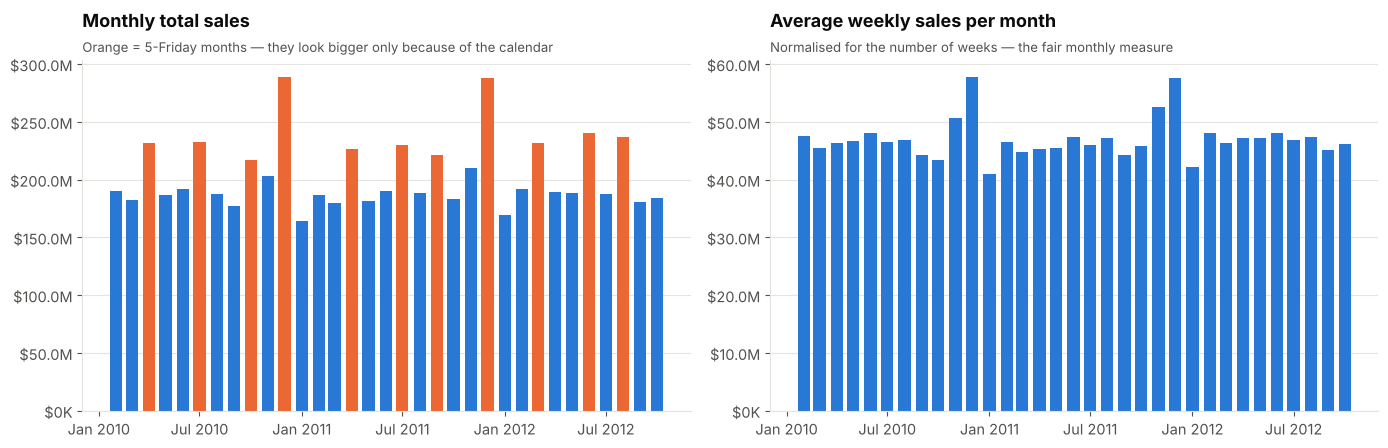

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharex=True)

colors = [ORANGE if n == 5 else BLUE for n in monthly.n_weeks]
axes[0].bar(monthly.index, monthly.total_sales, width=22, color=colors)
axes[0].yaxis.set_major_formatter(MONEY)
title(axes[0], "Monthly total sales", "Orange = 5-Friday months — they look bigger only because of the calendar")
axes[1].bar(monthly.index, monthly.avg_weekly_sales, width=22, color=BLUE)
axes[1].yaxis.set_major_formatter(MONEY)
title(axes[1], "Average weekly sales per month", "Normalised for the number of weeks — the fair monthly measure")
for ax in axes:
    date_axis(ax)
plt.tight_layout(); plt.show()

## 5. Trend analysis
First the weekly series with holiday weeks highlighted, then the **underlying level** (seasonality removed) and year-over-year growth on a like-for-like basis.

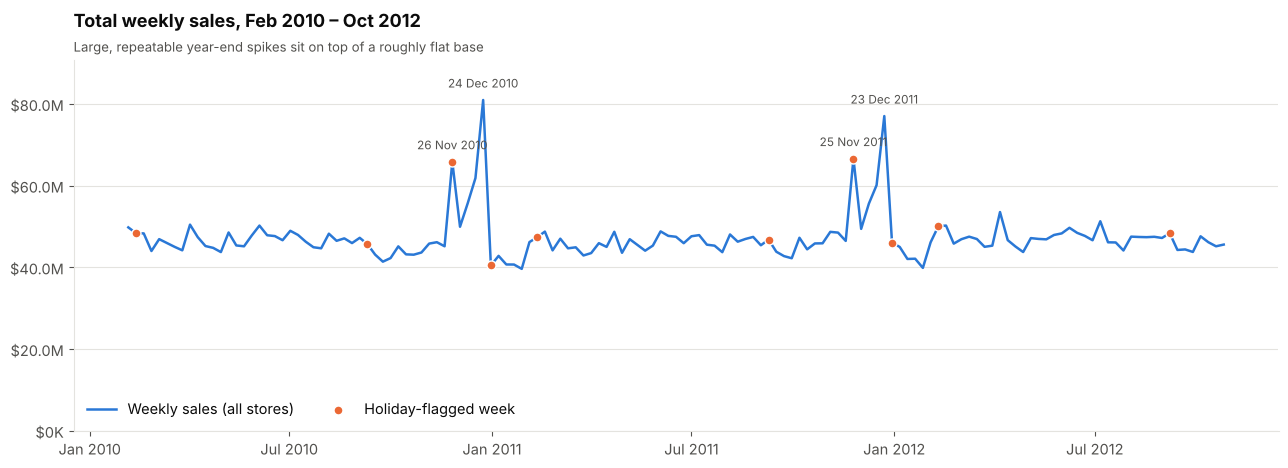

In [6]:
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(weekly.index, weekly.values, color=BLUE, lw=1.8, label="Weekly sales (all stores)")
hol = weekly[weekly_is_holiday]
ax.scatter(hol.index, hol.values, s=42, color=ORANGE, edgecolor="white", linewidth=1, zorder=3,
           label="Holiday-flagged week")

# label the four biggest weeks
for d, v in weekly.nlargest(4).items():
    ax.annotate(f"{d:%d %b %Y}", (d, v), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=8.5, color=INK2)
ax.yaxis.set_major_formatter(MONEY); date_axis(ax)
ax.set_ylim(0, weekly.max() * 1.12)
title(ax, "Total weekly sales, Feb 2010 – Oct 2012",
      "Large, repeatable year-end spikes sit on top of a roughly flat base")
ax.legend(loc="lower left", ncol=2)
plt.tight_layout(); plt.show()

### 5.1 Annual summary and like-for-like year-over-year growth
2010 starts in February and 2012 ends in October, so calendar-year totals are **not** comparable. The fair comparison is the same window every year — **February to October** (39 weeks each) — using average weekly sales.

In [7]:
def lfl_window(frame, year):
    # Feb–Oct rows for a given year
    return frame[(frame.Year == year) & frame.Date.dt.month.between(2, 10)]

rows = []
for y in (2010, 2011, 2012):
    w = lfl_window(df, y)
    rows.append({"Year": y, "Weeks (Feb–Oct)": w.Date.nunique(),
                 "Sales (Feb–Oct)": w.Weekly_Sales.sum(),
                 "Avg weekly sales": w.Weekly_Sales.sum() / w.Date.nunique()})
annual = pd.DataFrame(rows).set_index("Year")
annual["YoY growth"] = annual["Avg weekly sales"].pct_change()

annual.assign(**{"Sales (Feb–Oct)": annual["Sales (Feb–Oct)"].map(money),
                 "Avg weekly sales": annual["Avg weekly sales"].map(money),
                 "YoY growth": annual["YoY growth"].map(lambda v: "" if pd.isna(v) else f"{v:+.1%}")})

,Weeks (Feb–Oct),Sales (Feb–Oct),Avg weekly sales,YoY growth
Year,,,,
2010,39,"$1,797.3M",$46.1M,
2011,39,"$1,786.3M",$45.8M,-0.6%
2012,39,"$1,831.2M",$47.0M,+2.5%


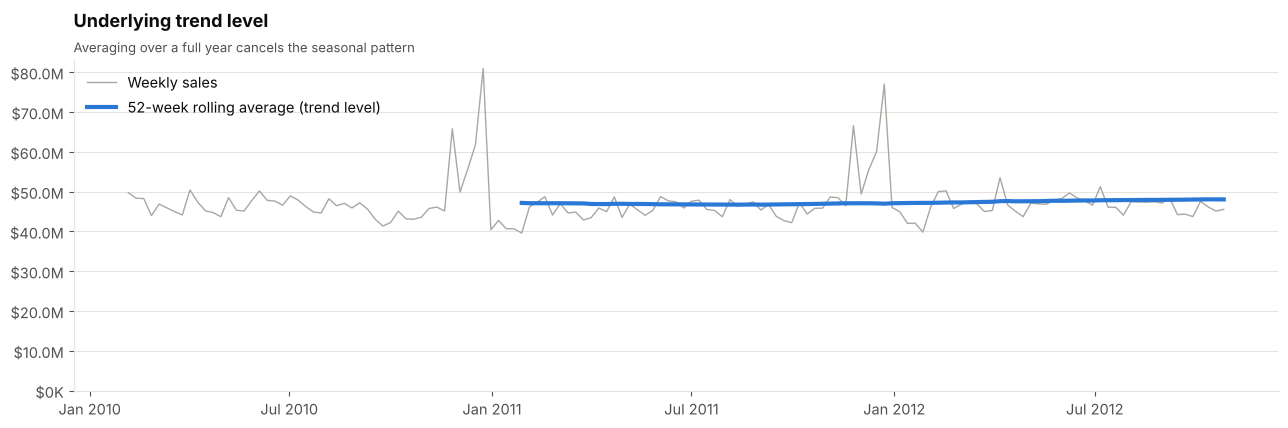

52-wk average moved from $47.2M (Jan 2011) to $48.0M (Oct 2012): +1.9% over 1.7 years (~+1.1% per year).


In [8]:
# Seasonality-free view of the trend: rolling 52-week average (one full seasonal cycle)
ma52 = weekly.rolling(52).mean()

fig, ax = plt.subplots(figsize=(13, 4.4))
ax.plot(weekly.index, weekly.values, color=OTHER, lw=1, label="Weekly sales")
ax.plot(ma52.index, ma52.values, color=BLUE, lw=3, label="52-week rolling average (trend level)")
ax.yaxis.set_major_formatter(MONEY); date_axis(ax); ax.set_ylim(0)
title(ax, "Underlying trend level", "Averaging over a full year cancels the seasonal pattern")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

first, last = ma52.dropna().iloc[0], ma52.dropna().iloc[-1]
span_years = (ma52.dropna().index[-1] - ma52.dropna().index[0]).days / 365.25
print(f"52-wk average moved from {money(first)} ({ma52.dropna().index[0]:%b %Y}) to {money(last)} "
      f"({ma52.dropna().index[-1]:%b %Y}): {last/first-1:+.1%} over {span_years:.1f} years "
      f"(~{(last/first)**(1/span_years)-1:+.1%} per year).")

## 6. Moving averages
A moving average smooths noise but **lags** the data; the longer the window, the smoother and the later it reacts. Three windows are compared on the weekly series:

| Window | Smooths | Reading |
|---|---|---|
| 4 weeks (~1 month) | week-to-week noise | still shows holiday spikes |
| 13 weeks (~1 quarter) | holiday spikes | shows quarter-scale swings |
| 52 weeks (1 year) | the whole seasonal cycle | pure trend |

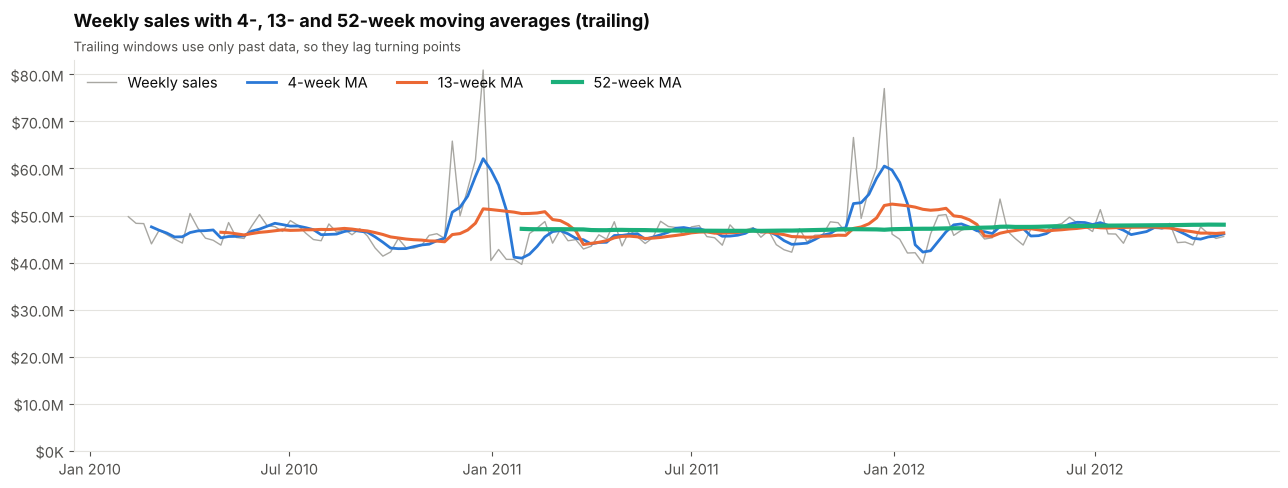

In [9]:
ma = {k: weekly.rolling(k).mean() for k in (4, 13, 52)}

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(weekly.index, weekly.values, color=OTHER, lw=1, label="Weekly sales")
ax.plot(ma[4].index,  ma[4].values,  color=BLUE,   lw=2,   label="4-week MA")
ax.plot(ma[13].index, ma[13].values, color=ORANGE, lw=2.2, label="13-week MA")
ax.plot(ma[52].index, ma[52].values, color=AQUA,   lw=3,   label="52-week MA")
ax.yaxis.set_major_formatter(MONEY); date_axis(ax); ax.set_ylim(0)
title(ax, "Weekly sales with 4-, 13- and 52-week moving averages (trailing)",
      "Trailing windows use only past data, so they lag turning points")
ax.legend(loc="upper left", ncol=4)
plt.tight_layout(); plt.show()

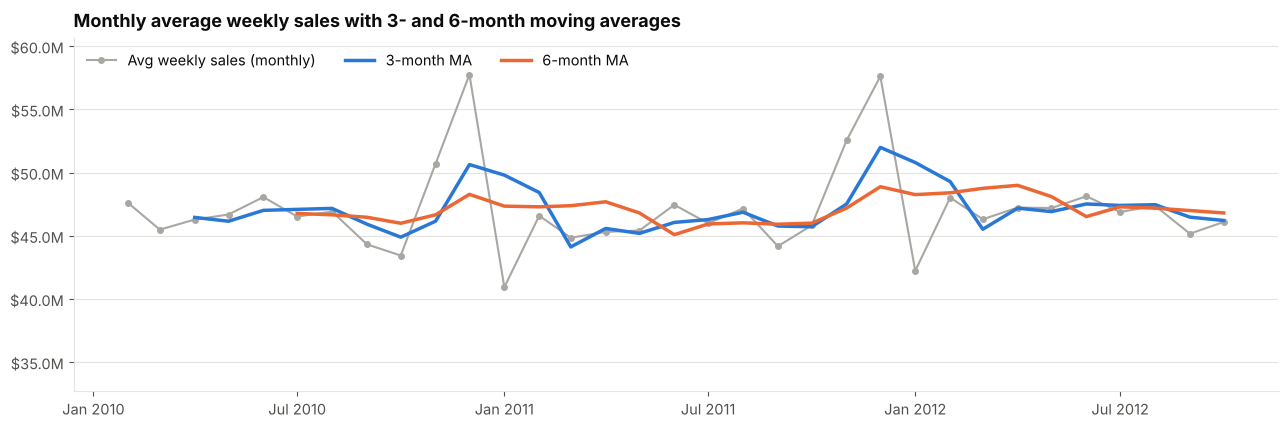

In [10]:
# Monthly view: 3- and 6-month moving averages of the normalised monthly measure
m = monthly.avg_weekly_sales
fig, ax = plt.subplots(figsize=(13, 4.4))
ax.plot(m.index, m.values, color=OTHER, lw=1.5, marker="o", ms=4, label="Avg weekly sales (monthly)")
ax.plot(m.index, m.rolling(3).mean(), color=BLUE,   lw=2.5, label="3-month MA")
ax.plot(m.index, m.rolling(6).mean(), color=ORANGE, lw=2.5, label="6-month MA")
ax.yaxis.set_major_formatter(MONEY); date_axis(ax); ax.set_ylim(m.min() * 0.8, m.max() * 1.05)
title(ax, "Monthly average weekly sales with 3- and 6-month moving averages")
ax.legend(loc="upper left", ncol=3)
plt.tight_layout(); plt.show()

## 7. Seasonality
Four complementary views: (1) a classical decomposition, (2) the seasonal pattern by week of year, (3) a year × month heatmap, and (4) a holiday-effect analysis.

### 7.1 STL decomposition
STL (*Seasonal-Trend decomposition using Loess*) splits the series into **trend × seasonal × residual**. It is run on the **log** of sales so that the seasonal effect is *multiplicative* (a holiday week lifts sales by a percentage, not a fixed dollar amount), then converted back with `exp()`. The period is 52 weeks.

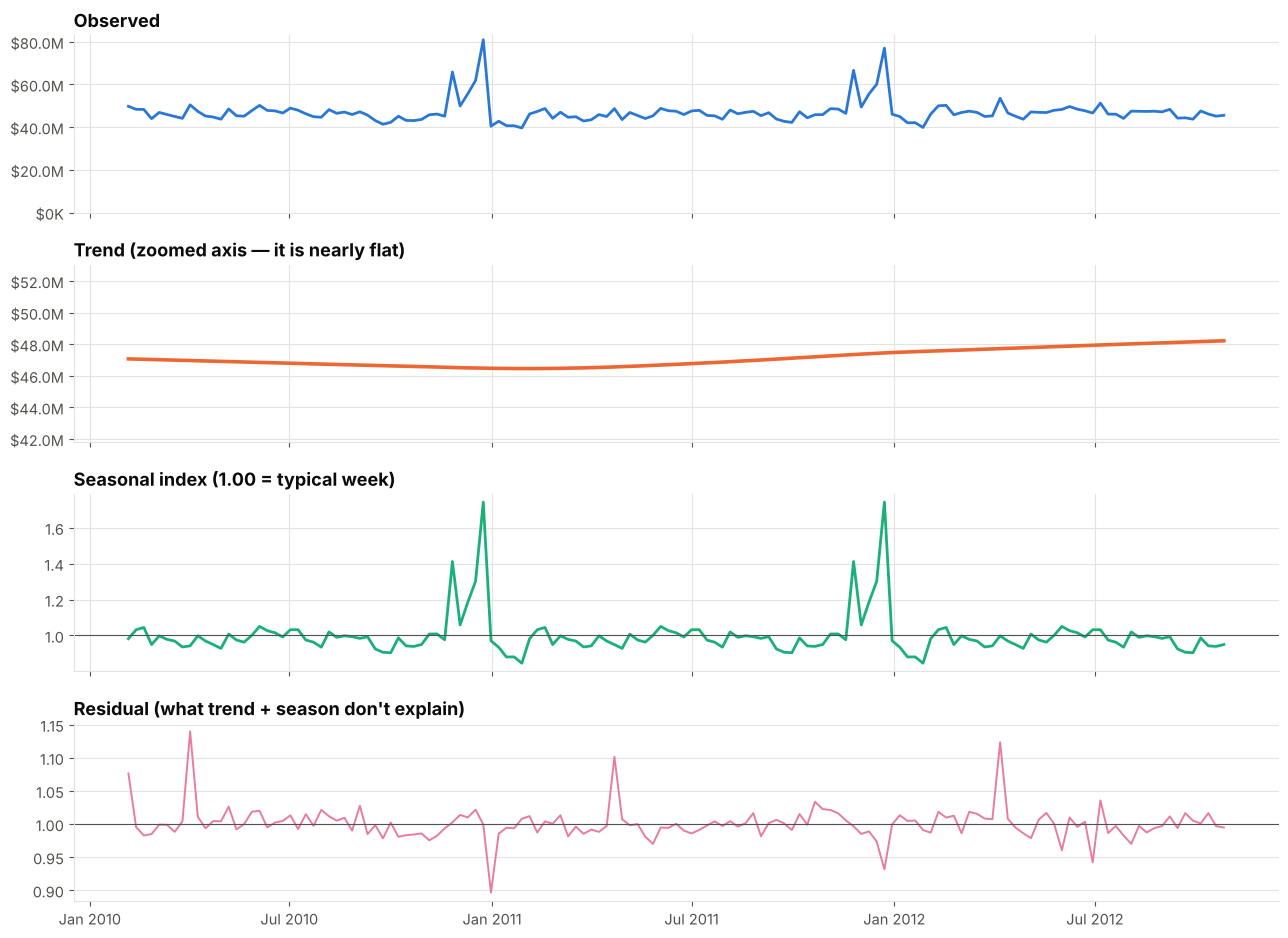

Seasonal strength: 0.94   |   Trend strength: 0.19   (log scale, 0 = none, 1 = very strong)


In [11]:
# seasonal_deg=0 + wide window => the seasonal pattern is a (robust) average across years.
# (STL defaults interpolate the only 2-3 points per week-of-year, which overfits and leaves ~0 residual.)
stl = STL(np.log(weekly), period=52, robust=True, seasonal=21, seasonal_deg=0).fit()
trend    = np.exp(stl.trend)
seasonal = np.exp(stl.seasonal)       # multiplicative seasonal index (1.00 = typical week)
resid    = np.exp(stl.resid)

fig, axes = plt.subplots(4, 1, figsize=(13, 9.5), sharex=True)
axes[0].plot(weekly.index, weekly, color=BLUE);               axes[0].set_title("Observed")
axes[1].plot(trend.index, trend, color=ORANGE, lw=2.6);       axes[1].set_title("Trend (zoomed axis — it is nearly flat)")
axes[2].plot(seasonal.index, seasonal, color=AQUA);           axes[2].set_title("Seasonal index (1.00 = typical week)")
axes[2].axhline(1, color=INK2, lw=0.8)
axes[3].plot(resid.index, resid, color=MAGENTA, lw=1.4);      axes[3].set_title("Residual (what trend + season don't explain)")
axes[3].axhline(1, color=INK2, lw=0.8)
axes[0].yaxis.set_major_formatter(MONEY); axes[0].set_ylim(0)
axes[1].yaxis.set_major_formatter(MONEY); axes[1].set_ylim(trend.min() * 0.9, trend.max() * 1.1)
date_axis(axes[3])
plt.tight_layout(); plt.show()

# Strength of trend and seasonality (Hyndman & Athanasopoulos): 0 = none, 1 = very strong
var = np.var
Fs = max(0, 1 - var(stl.resid) / var(stl.seasonal + stl.resid))
Ft = max(0, 1 - var(stl.resid) / var(stl.trend + stl.resid))
print(f"Seasonal strength: {Fs:.2f}   |   Trend strength: {Ft:.2f}   (log scale, 0 = none, 1 = very strong)")

### 7.2 Seasonal pattern by week of year
Each line is one year, aligned by week of year. Where the lines overlap, the pattern repeats year after year — that is seasonality.

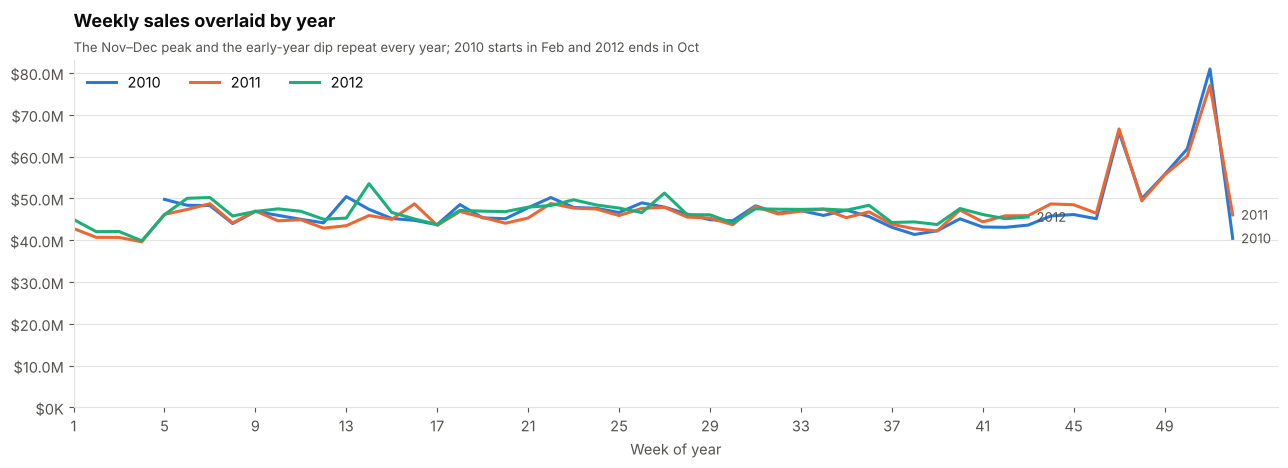

In [12]:
fig, ax = plt.subplots(figsize=(13, 4.8))
yr_colors = {2010: BLUE, 2011: ORANGE, 2012: AQUA}
for y, g in weekly.groupby(weekly.index.year):
    wk = g.index.isocalendar().week.astype(int)
    ax.plot(wk.values, g.values, color=yr_colors[y], lw=2.2, label=str(y))
    ax.annotate(str(y), (wk.values[-1], g.values[-1]), xytext=(6, 0), textcoords="offset points",
                color=INK2, fontsize=9.5, va="center")
ax.set_xlim(1, 54); ax.set_ylim(0)
ax.set_xticks(range(1, 53, 4)); ax.set_xlabel("Week of year")
ax.yaxis.set_major_formatter(MONEY); ax.grid(axis="x", visible=False)
title(ax, "Weekly sales overlaid by year",
      "The Nov–Dec peak and the early-year dip repeat every year; 2010 starts in Feb and 2012 ends in Oct")
ax.legend(loc="upper left", ncol=3)
plt.tight_layout(); plt.show()

### 7.3 Month-of-year pattern
Average weekly sales per month, by year (heatmap, $M per week), and the typical seasonal index by month from the STL decomposition.

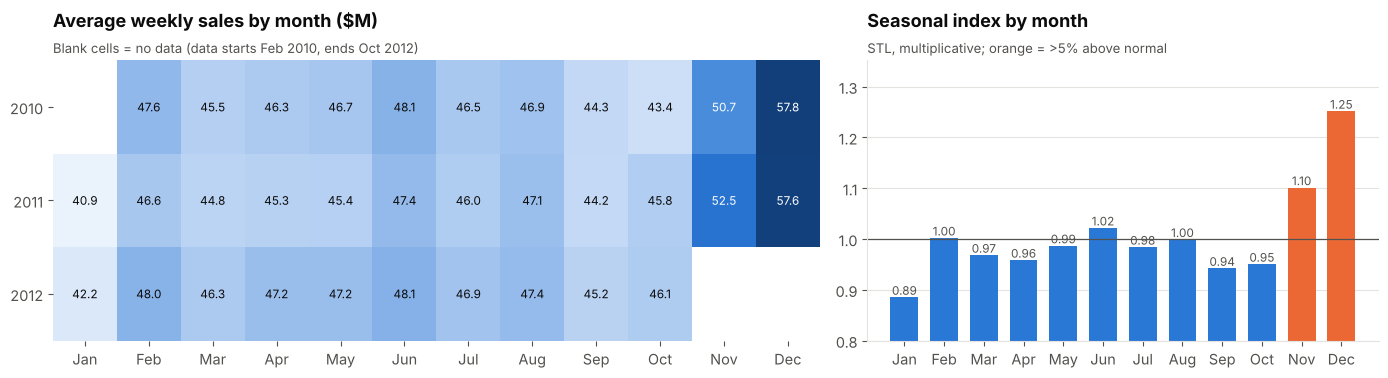

In [13]:
heat = (monthly.assign(Year=monthly.index.year, Mon=monthly.index.month)
               .pivot(index="Year", columns="Mon", values="avg_weekly_sales") / 1e6)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.9), gridspec_kw={"width_ratios": [1.5, 1]})
annotated_heatmap(axes[0], heat, SEQ, fmt="{:.1f}", xticks=MONTHS)
title(axes[0], "Average weekly sales by month ($M)", "Blank cells = no data (data starts Feb 2010, ends Oct 2012)")

month_idx = (seasonal.groupby(seasonal.index.month).mean())
bars = axes[1].bar(MONTHS, month_idx.values, color=[ORANGE if v > 1.05 else BLUE for v in month_idx.values], width=0.7)
axes[1].axhline(1, color=INK2, lw=0.9)
axes[1].set_ylim(0.8, month_idx.max() * 1.08)
axes[1].grid(axis="x", visible=False)
for r, v in zip(bars, month_idx.values):
    axes[1].text(r.get_x() + r.get_width()/2, v + 0.005, f"{v:.2f}", ha="center", fontsize=8.5, color=INK2)
title(axes[1], "Seasonal index by month", "STL, multiplicative; orange = >5% above normal")
plt.tight_layout(); plt.show()

### 7.4 Holiday effect
The retailer flags four holiday weeks a year (`IsHoliday`). How much do they lift sales **relative to the underlying trend**, and are they really the biggest weeks?

,weeks,avg_sales,avg_lift_vs_trend
event,,,
Thanksgiving,2,$66.2M,+41.1%
Super Bowl,3,$48.6M,+3.2%
Labor Day,3,$46.9M,-0.8%
Christmas,2,$43.2M,-8.0%


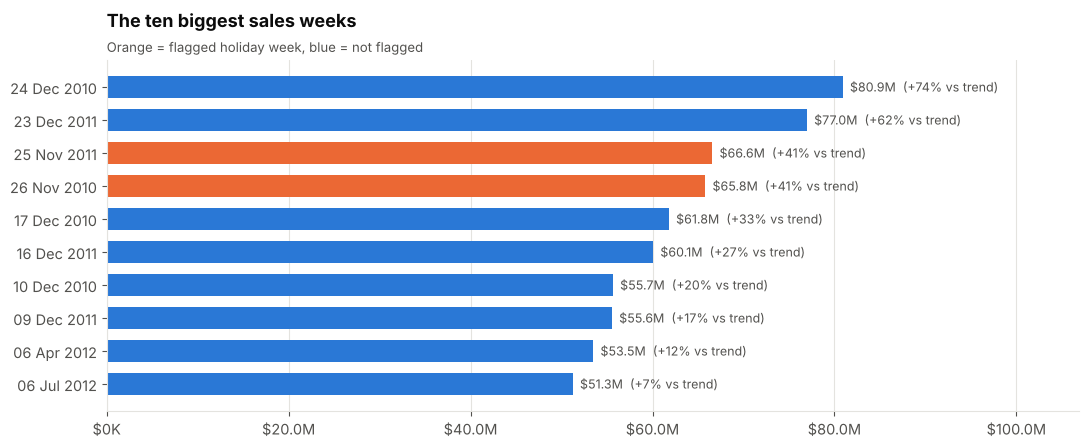

In [14]:
wk = pd.DataFrame({"sales": weekly, "holiday": weekly_is_holiday, "trend": trend})
wk["lift_vs_trend"] = wk.sales / wk.trend - 1
event = {2: "Super Bowl", 9: "Labor Day", 11: "Thanksgiving", 12: "Christmas"}
wk["event"] = np.where(wk.holiday, wk.index.month.map(event), "")

# Lift of flagged weeks, by event
hol_tbl = (wk[wk.holiday].groupby("event")
             .agg(weeks=("sales", "size"), avg_sales=("sales", "mean"), avg_lift_vs_trend=("lift_vs_trend", "mean"))
             .sort_values("avg_lift_vs_trend", ascending=False))
hol_tbl["avg_sales"] = hol_tbl.avg_sales.map(money)
hol_tbl["avg_lift_vs_trend"] = hol_tbl.avg_lift_vs_trend.map("{:+.1%}".format)
display(hol_tbl)

# Ten biggest weeks overall
top10 = wk.nlargest(10, "sales").sort_values("sales")
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.barh([f"{d:%d %b %Y}" for d in top10.index], top10.sales,
        color=[ORANGE if h else BLUE for h in top10.holiday], height=0.65)
for i, (d, r) in enumerate(top10.iterrows()):
    ax.text(r.sales, i, f"  {money(r.sales)}  ({r.lift_vs_trend:+.0%} vs trend)", va="center", fontsize=9, color=INK2)
ax.xaxis.set_major_formatter(MONEY); ax.set_xlim(0, top10.sales.max() * 1.32); ax.grid(axis="y", visible=False)
title(ax, "The ten biggest sales weeks", "Orange = flagged holiday week, blue = not flagged")
plt.tight_layout(); plt.show()

**Takeaway.** The `IsHoliday` flag does not capture the single biggest retail event: the **week before Christmas is not flagged**, yet it is the largest week of both years, bigger even than Thanksgiving week. The flagged Christmas week (the one *after* Christmas) actually sells **below** trend. Any model that relies only on `IsHoliday` would miss it, which is why the seasonal component (week-of-year) matters.

## 8. Revenue by product (department) over time
Departments are anonymised numbers. We look at concentration (who matters), the revenue mix over time, each department's own seasonal fingerprint, and like-for-like growth.

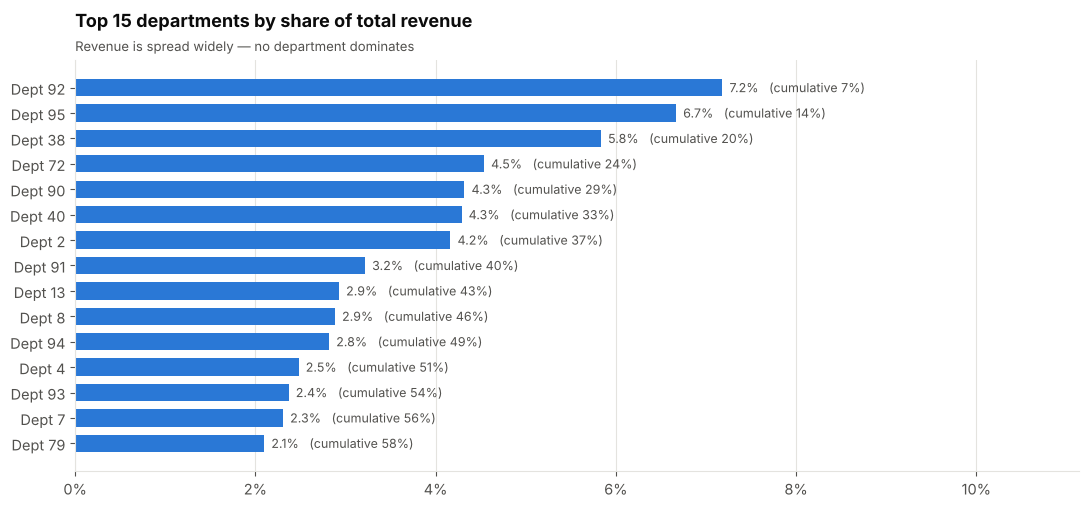

Top 5 departments = 29% of revenue; top 10 = 46%; top 20 = 68%.


In [15]:
dept_total = df.groupby("Dept").Weekly_Sales.sum().sort_values(ascending=False)
dept_share = dept_total / dept_total.sum()
top15 = dept_share.head(15)

fig, ax = plt.subplots(figsize=(11, 5.2))
y = np.arange(len(top15))[::-1]
ax.barh(y, top15.values, color=BLUE, height=0.68)
cum = top15.cumsum()
for yi, (d, s) in zip(y, top15.items()):
    ax.text(s, yi, f"  {s:.1%}   (cumulative {cum[d]:.0%})", va="center", fontsize=9, color=INK2)
ax.set_yticks(y); ax.set_yticklabels([f"Dept {d}" for d in top15.index])
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_xlim(0, top15.max() * 1.55)
ax.grid(axis="y", visible=False)
title(ax, "Top 15 departments by share of total revenue", "Revenue is spread widely — no department dominates")
plt.tight_layout(); plt.show()
print(f"Top 5 departments = {dept_share.head(5).sum():.0%} of revenue; top 10 = {dept_share.head(10).sum():.0%}; "
      f"top 20 = {dept_share.head(20).sum():.0%}.")

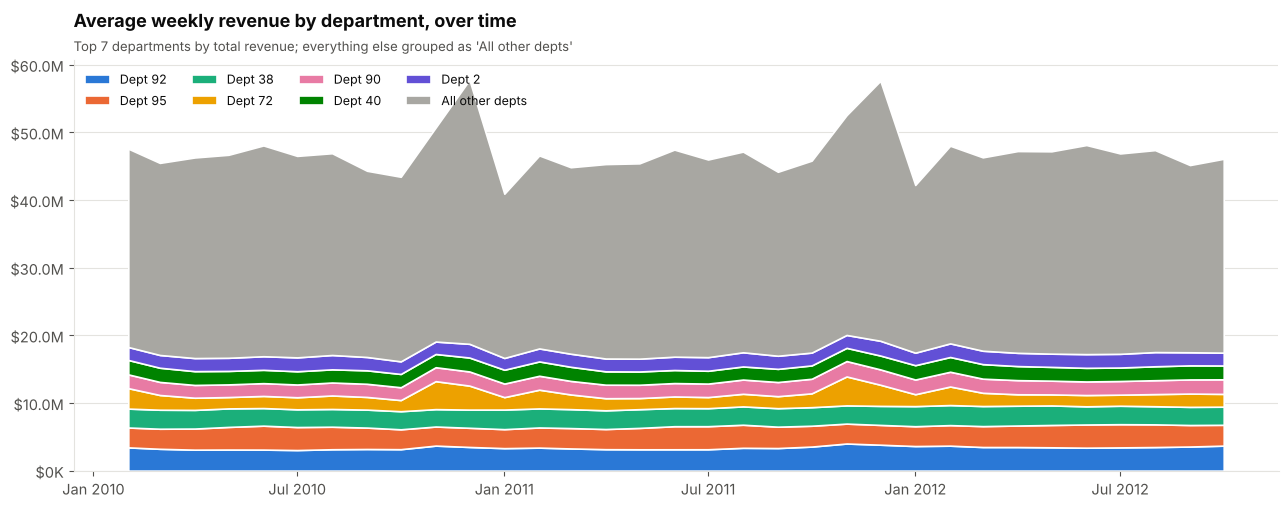

In [16]:
# Monthly average weekly sales by department: top 7 + "Other"
TOP_DEPTS = list(dept_total.head(7).index)
df["DeptGroup"] = np.where(df.Dept.isin(TOP_DEPTS), "Dept " + df.Dept.astype(str), "All other depts")

order = [f"Dept {d}" for d in TOP_DEPTS] + ["All other depts"]
dept_m = (df.pivot_table(index="Month", columns="DeptGroup", values="Weekly_Sales", aggfunc="sum")
            .div(monthly.n_weeks, axis=0)[order])
DEPT_COLOR = dict(zip(order, SERIES + [OTHER]))

fig, ax = plt.subplots(figsize=(13, 5.2))
ax.stackplot(dept_m.index, dept_m.T.values, labels=order, colors=[DEPT_COLOR[c] for c in order],
             edgecolor="white", linewidth=1.2)
ax.yaxis.set_major_formatter(MONEY); date_axis(ax)
title(ax, "Average weekly revenue by department, over time",
      "Top 7 departments by total revenue; everything else grouped as 'All other depts'")
ax.legend(loc="upper left", ncol=4, fontsize=9)
plt.tight_layout(); plt.show()

### 8.1 Each department's seasonal fingerprint
Index = a department's average weekly sales in that calendar month ÷ its own average across the year. **Orange = above its normal, blue = below** (100 = typical). This shows *which* departments drive the year-end peak.

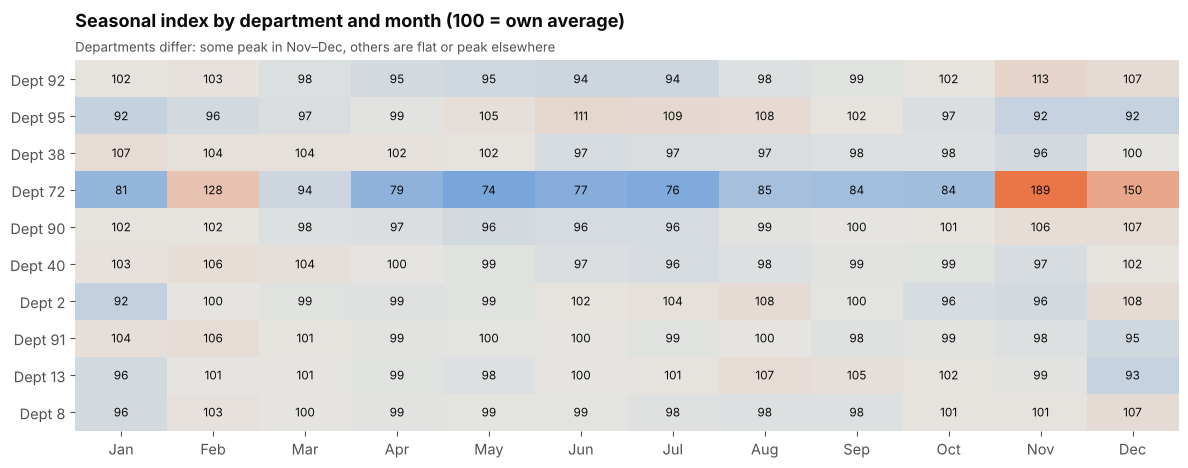

In [17]:
top10_depts = list(dept_total.head(10).index)
dm = (df[df.Dept.isin(top10_depts)]
        .pivot_table(index="Month", columns="Dept", values="Weekly_Sales", aggfunc="sum")
        .div(monthly.n_weeks, axis=0))
dm["Mon"] = dm.index.month
fingerprint = dm.groupby("Mon").mean()                       # average across years, by calendar month
fingerprint = (fingerprint / fingerprint.mean()).T * 100       # 100 = department's own average month
fingerprint = fingerprint.loc[top10_depts]

fig, ax = plt.subplots(figsize=(12, 4.8))
annotated_heatmap(ax, fingerprint, DIV, norm=TwoSlopeNorm(vcenter=100, vmin=55, vmax=200),
                  fmt="{:.0f}", xticks=MONTHS, yticks=[f"Dept {d}" for d in fingerprint.index])
title(ax, "Seasonal index by department and month (100 = own average)",
      "Departments differ: some peak in Nov–Dec, others are flat or peak elsewhere")
plt.tight_layout(); plt.show()

### 8.2 Like-for-like growth by department
Average weekly sales over the same 39-week window (Feb–Oct), **2012 vs 2011**, for the 20 biggest departments.

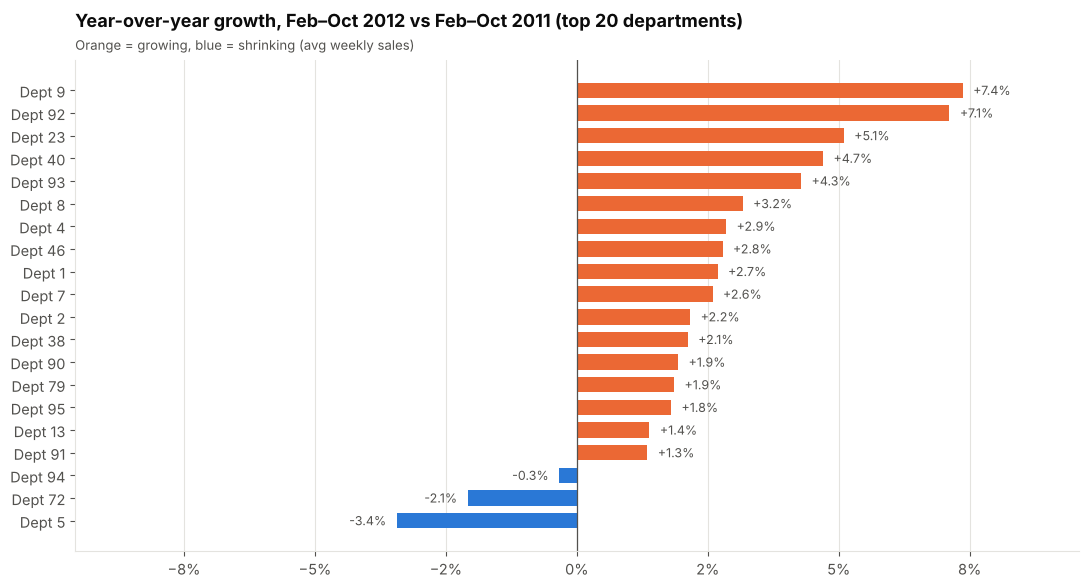

In [18]:
top20 = list(dept_total.head(20).index)
def lfl_by(frame, year, by):
    w = lfl_window(frame, year)
    return w.groupby(by).Weekly_Sales.sum() / w.Date.nunique()

g = (lfl_by(df, 2012, "Dept") / lfl_by(df, 2011, "Dept") - 1).loc[top20].sort_values()

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh([f"Dept {d}" for d in g.index], g.values, color=[ORANGE if v >= 0 else BLUE for v in g.values], height=0.68)
for i, v in enumerate(g.values):
    ax.text(v + (0.002 if v >= 0 else -0.002), i, f"{v:+.1%}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color=INK2)
ax.axvline(0, color=INK2, lw=0.9)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.grid(axis="y", visible=False)
lim = max(abs(g.min()), g.max()) * 1.3; ax.set_xlim(-lim, lim)
title(ax, "Year-over-year growth, Feb–Oct 2012 vs Feb–Oct 2011 (top 20 departments)",
      "Orange = growing, blue = shrinking (avg weekly sales)")
plt.tight_layout(); plt.show()

## 9. Revenue by region (store type & store) over time
> **Note on "region".** The dataset has no geographic column, so **store format (`Type` A/B/C)** is used as the regional proxy, with individual stores as a finer cut. Type is strongly tied to store size, which is why it explains so much of the difference.

In [19]:
type_profile = (stores.merge(df.groupby("Store").Weekly_Sales.sum().rename("total"), on="Store")
                .groupby("Type").agg(stores=("Store", "size"), avg_size_sqft=("Size", "mean"), total_sales=("total", "sum")))
type_profile["share_of_revenue"] = type_profile.total_sales / type_profile.total_sales.sum()
n_weeks_total = df.Date.nunique()
type_profile["avg_weekly_sales_per_store"] = type_profile.total_sales / type_profile.stores / n_weeks_total
type_profile["weekly_sales_per_sqft"] = type_profile.avg_weekly_sales_per_store / type_profile.avg_size_sqft

type_profile.assign(avg_size_sqft=type_profile.avg_size_sqft.map("{:,.0f}".format),
                    total_sales=type_profile.total_sales.map(money),
                    share_of_revenue=type_profile.share_of_revenue.map("{:.1%}".format),
                    avg_weekly_sales_per_store=type_profile.avg_weekly_sales_per_store.map(money),
                    weekly_sales_per_sqft=type_profile.weekly_sales_per_sqft.map("${:.2f}".format))

,stores,avg_size_sqft,total_sales,share_of_revenue,avg_weekly_sales_per_store,weekly_sales_per_sqft
Type,,,,,,
A,22,"177,248","$4,331.0M",64.3%,$1.4M,$7.77
B,17,"101,191","$2,000.7M",29.7%,$823K,$8.13
C,6,"40,542",$405.5M,6.0%,$473K,$11.66


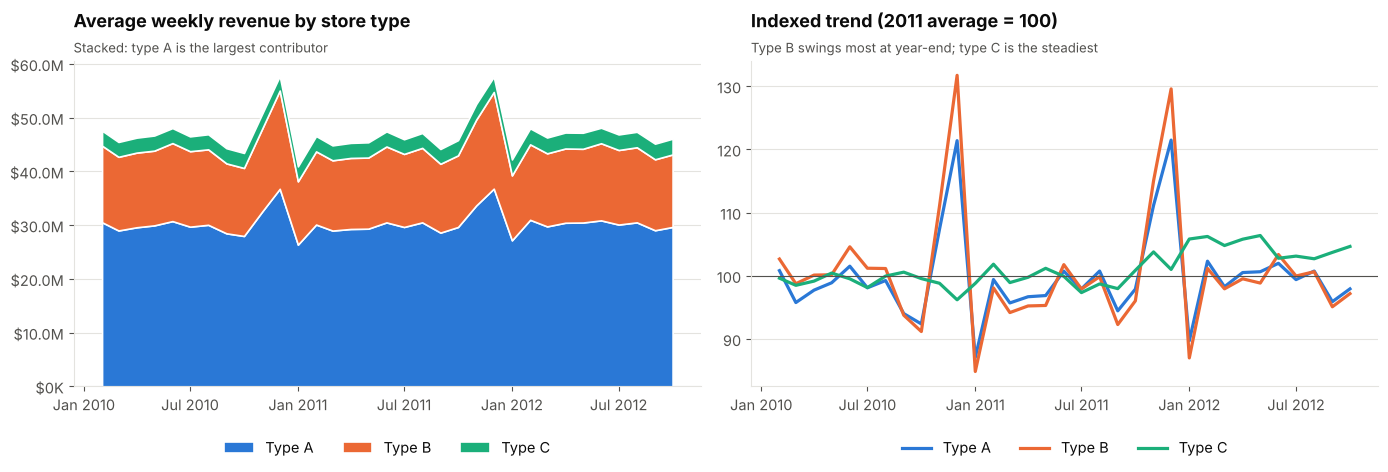

In [20]:
TYPE_COLOR = {"A": BLUE, "B": ORANGE, "C": AQUA}
type_m = (df.pivot_table(index="Month", columns="Type", values="Weekly_Sales", aggfunc="sum")
            .div(monthly.n_weeks, axis=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.9))
axes[0].stackplot(type_m.index, type_m.T.values, labels=[f"Type {t}" for t in type_m.columns],
                  colors=[TYPE_COLOR[t] for t in type_m.columns], edgecolor="white", linewidth=1.2)
axes[0].yaxis.set_major_formatter(MONEY); date_axis(axes[0])
title(axes[0], "Average weekly revenue by store type", "Stacked: type A is the largest contributor")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)

# Indexed to each type's own 2011 average so different-sized types are comparable on ONE axis
base = type_m[type_m.index.year == 2011].mean()
idx = type_m / base * 100
for t in idx.columns:
    axes[1].plot(idx.index, idx[t], color=TYPE_COLOR[t], lw=2.3, label=f"Type {t}")
axes[1].axhline(100, color=INK2, lw=0.8)
date_axis(axes[1])
title(axes[1], "Indexed trend (2011 average = 100)", "Type B swings most at year-end; type C is the steadiest")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.tight_layout(); plt.show()

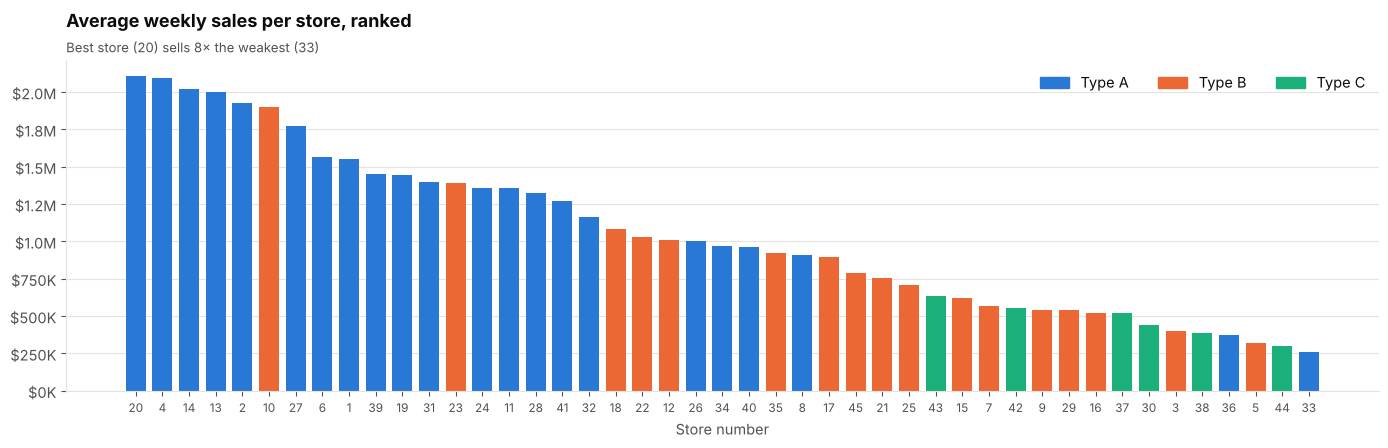

In [21]:
# Store-level ranking: average weekly sales per store, coloured by type
store_avg = (df.groupby("Store").Weekly_Sales.sum() / n_weeks_total).sort_values(ascending=False)
store_type = stores.set_index("Store").Type

fig, ax = plt.subplots(figsize=(14, 4.6))
ax.bar(range(len(store_avg)), store_avg.values, color=[TYPE_COLOR[store_type[s]] for s in store_avg.index], width=0.75)
ax.set_xticks(range(len(store_avg))); ax.set_xticklabels(store_avg.index, fontsize=8.5)
ax.set_xlabel("Store number"); ax.yaxis.set_major_formatter(MONEY); ax.grid(axis="x", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=f"Type {t}") for t, c in TYPE_COLOR.items()], loc="upper right", ncol=3)
title(ax, "Average weekly sales per store, ranked",
      f"Best store ({store_avg.index[0]}) sells {store_avg.iloc[0]/store_avg.iloc[-1]:.0f}× the weakest ({store_avg.index[-1]})")
plt.tight_layout(); plt.show()

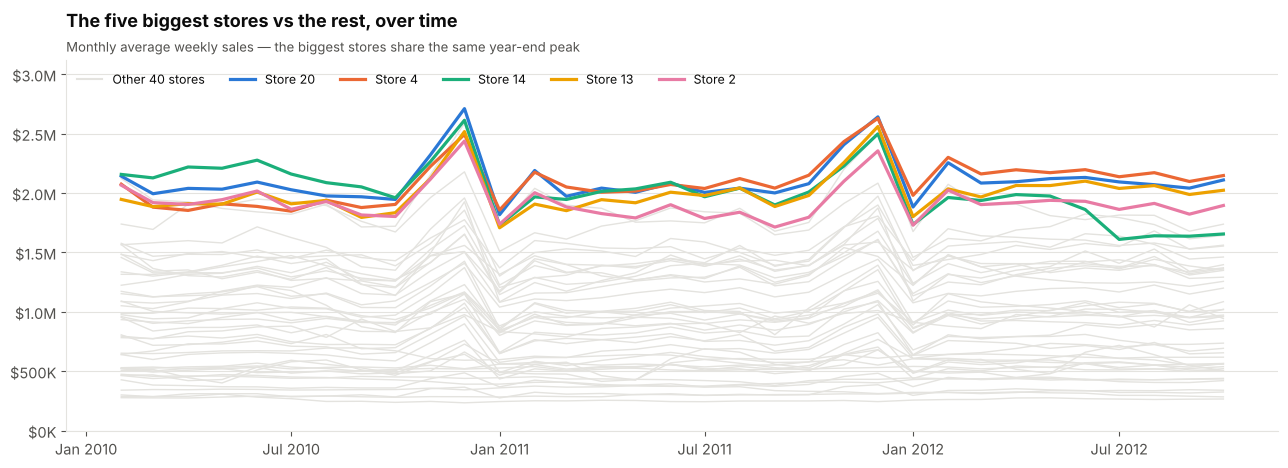

In [22]:
# Top-5 stores over time vs the rest (monthly avg weekly sales, per store)
top5 = list(store_avg.head(5).index)
store_m = (df.pivot_table(index="Month", columns="Store", values="Weekly_Sales", aggfunc="sum")
             .div(monthly.n_weeks, axis=0))
fig, ax = plt.subplots(figsize=(13, 4.8))
others = store_m.drop(columns=top5)
for s in others.columns:
    ax.plot(others.index, others[s], color=GRID, lw=1, zorder=1)
ax.plot([], [], color=GRID, lw=1.5, label="Other 40 stores")
for s, c in zip(top5, SERIES):
    ax.plot(store_m.index, store_m[s], color=c, lw=2.3, label=f"Store {s}", zorder=2)
ax.yaxis.set_major_formatter(MONEY); date_axis(ax); ax.set_ylim(0, store_m.max().max() * 1.15)
title(ax, "The five biggest stores vs the rest, over time",
      "Monthly average weekly sales — the biggest stores share the same year-end peak")
ax.legend(loc="upper left", ncol=6, fontsize=9)
plt.tight_layout(); plt.show()

## 10. Product × region over time
Combining both cuts: what each store type sells (department mix), and how the top departments evolve within each store type.

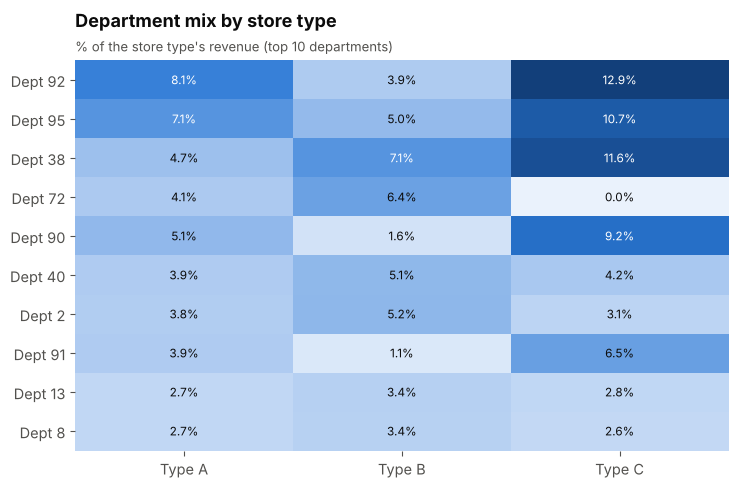

In [23]:
mix = (df[df.Dept.isin(top10_depts)]
         .pivot_table(index="Dept", columns="Type", values="Weekly_Sales", aggfunc="sum"))
mix = (mix / df.groupby("Type").Weekly_Sales.sum() * 100).loc[top10_depts]   # % of each type's revenue

fig, ax = plt.subplots(figsize=(7.5, 5))
annotated_heatmap(ax, mix, SEQ, fmt="{:.1f}%", xticks=[f"Type {t}" for t in mix.columns],
                  yticks=[f"Dept {d}" for d in mix.index])
title(ax, "Department mix by store type", "% of the store type's revenue (top 10 departments)")
plt.tight_layout(); plt.show()

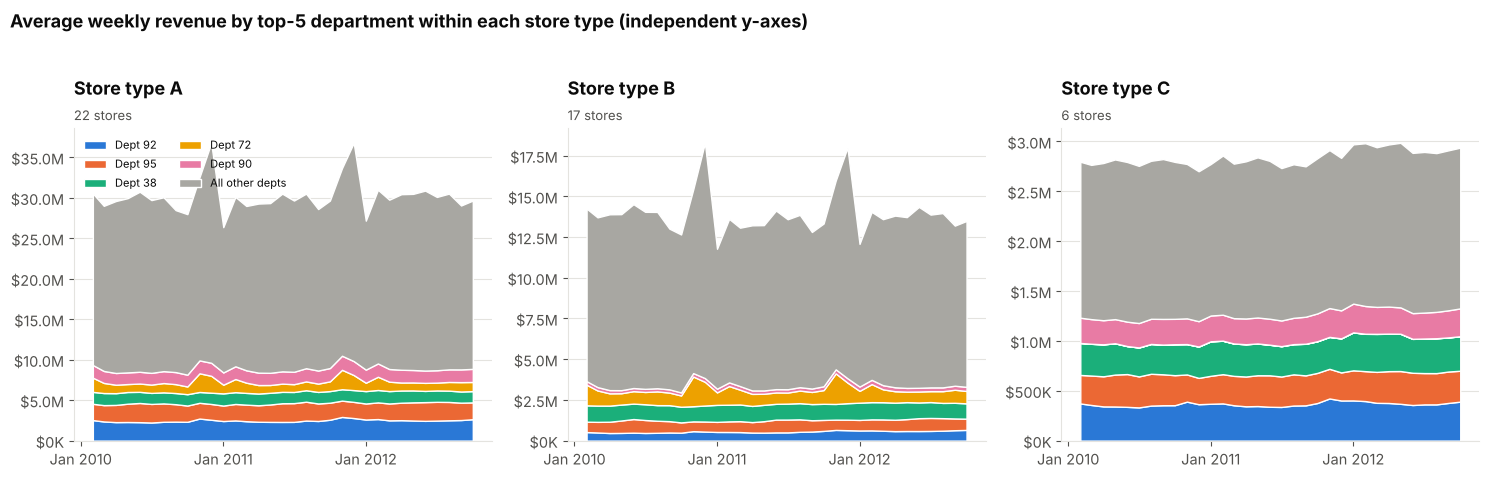

In [24]:
top5_depts = list(dept_total.head(5).index)
df["Dept5"] = np.where(df.Dept.isin(top5_depts), "Dept " + df.Dept.astype(str), "All other depts")
order5 = [f"Dept {d}" for d in top5_depts] + ["All other depts"]
colors5 = dict(zip(order5, SERIES[:5] + [OTHER]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, t in zip(axes, ["A", "B", "C"]):
    p = (df[df.Type == t].pivot_table(index="Month", columns="Dept5", values="Weekly_Sales", aggfunc="sum")
           .div(monthly.n_weeks, axis=0)[order5])
    ax.stackplot(p.index, p.T.values, colors=[colors5[c] for c in order5], edgecolor="white", linewidth=1,
                 labels=order5)
    ax.yaxis.set_major_formatter(MONEY); date_axis(ax, months=(1,))
    title(ax, f"Store type {t}", f"{(stores.Type == t).sum()} stores")
axes[0].legend(loc="upper left", fontsize=8, ncol=2)
fig.suptitle("Average weekly revenue by top-5 department within each store type (independent y-axes)",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

## 11. Bonus: forecasting
Goal: a simple, defensible forecast of **total weekly sales**. We compare transparent baselines with exponential smoothing:

| Model | Idea |
|---|---|
| Naive | next weeks = last week |
| Rolling mean (4 / 13 weeks) | next weeks = average of the last 4 / 13 weeks (flat) |
| Seasonal naive | next weeks = the same weeks one year earlier |
| Simple exponential smoothing (SES) | weighted average that decays exponentially; no trend/season |
| Holt-Winters (damped trend) | level + damped trend + multiplicative yearly seasonality |
| Holt-Winters (no trend) | level + multiplicative yearly seasonality |

**Evaluation: rolling-origin backtest.** With only ~2.75 years of data, a single hold-out is fragile. Instead the models are refitted on an *expanding* window and scored on three consecutive 13-week test periods (Feb–Apr, May–Jul, Aug–Oct 2012). Seasonal models need ≥ 2 years of history, so the first training window is 104 weeks.

Metrics: **MAE** (avg $ error), **RMSE** (penalises big misses), **MAPE** (avg % error).

In [25]:
H = 13                                   # forecast horizon (weeks) for each backtest fold
FOLD_STARTS = [104, 117, 130]            # training sizes: test windows are the next 13 weeks

def _hw(tr, h, trend, damped):
    fit = ExponentialSmoothing(tr, trend=trend, damped_trend=damped, seasonal="mul",
                               seasonal_periods=52, initialization_method="estimated").fit()
    return fit.forecast(h).values

MODELS = {
    "Naive (last week)":            lambda tr, h: np.repeat(tr.iloc[-1], h),
    "Rolling mean (4 wk)":          lambda tr, h: np.repeat(tr.iloc[-4:].mean(), h),
    "Rolling mean (13 wk)":         lambda tr, h: np.repeat(tr.iloc[-13:].mean(), h),
    "Seasonal naive (52 wk)":       lambda tr, h: tr.iloc[-52:].values[:h],
    "Simple exp. smoothing":        lambda tr, h: SimpleExpSmoothing(tr, initialization_method="estimated").fit().forecast(h).values,
    "Holt-Winters (damped trend)":  lambda tr, h: _hw(tr, h, "add", True),
    "Holt-Winters (no trend)":      lambda tr, h: _hw(tr, h, None, False),
}

def metrics(actual, pred):
    err = actual - pred
    return {"MAE": np.mean(np.abs(err)), "RMSE": np.sqrt(np.mean(err**2)), "MAPE": np.mean(np.abs(err / actual))}

records, fold_preds = [], {}
for i, n in enumerate(FOLD_STARTS, start=1):
    train_w, test_w = weekly.iloc[:n], weekly.iloc[n:n + H]
    for name, f in MODELS.items():
        pred = f(train_w, H)
        fold_preds[(i, name)] = pd.Series(pred, index=test_w.index)
        records.append({"fold": i, "model": name, **metrics(test_w.values, pred)})
bt = pd.DataFrame(records)

score = (bt.groupby("model")[["MAE", "RMSE", "MAPE"]].mean()
           .join(bt.pivot(index="model", columns="fold", values="MAPE").add_prefix("MAPE fold "))
           .sort_values("MAPE"))
score.assign(MAE=score.MAE.map(money), RMSE=score.RMSE.map(money),
             **{c: score[c].map("{:.1%}".format) for c in score.columns if "MAPE" in c})

,MAE,RMSE,MAPE,MAPE fold 1,MAPE fold 2,MAPE fold 3
model,,,,,,
Holt-Winters (no trend),$1.2M,$1.5M,2.5%,3.7%,2.3%,1.5%
Holt-Winters (damped trend),$1.2M,$1.5M,2.5%,3.8%,2.3%,1.5%
Seasonal naive (52 wk),$1.5M,$1.9M,3.1%,4.4%,3.0%,2.0%
Simple exp. smoothing,$2.4M,$2.8M,4.9%,7.7%,4.0%,2.9%
Rolling mean (13 wk),$2.4M,$2.8M,5.1%,9.9%,2.7%,2.9%
Rolling mean (4 wk),$2.5M,$2.9M,5.2%,10.1%,2.7%,2.8%
Naive (last week),$4.4M,$4.8M,9.2%,15.2%,7.8%,4.8%


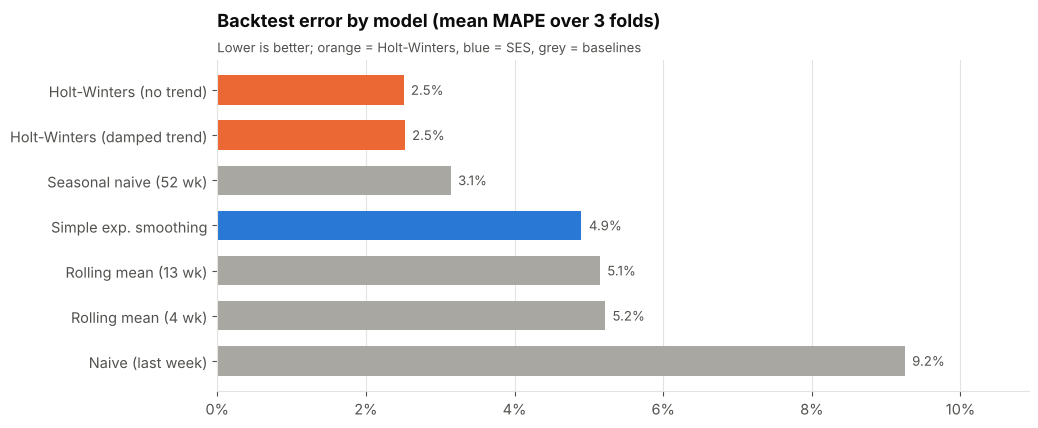

In [26]:
fig, ax = plt.subplots(figsize=(10.5, 4.4))
s = score.sort_values("MAPE", ascending=False)
bars = ax.barh(s.index, s.MAPE, height=0.65,
               color=[ORANGE if "Holt-Winters" in m else (BLUE if "smoothing" in m else OTHER) for m in s.index])
for b, v in zip(bars, s.MAPE):
    ax.text(v, b.get_y() + b.get_height()/2, f"  {v:.1%}", va="center", fontsize=9.5, color=INK2)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_xlim(0, s.MAPE.max() * 1.18); ax.grid(axis="y", visible=False)
title(ax, "Backtest error by model (mean MAPE over 3 folds)", "Lower is better; orange = Holt-Winters, blue = SES, grey = baselines")
plt.tight_layout(); plt.show()

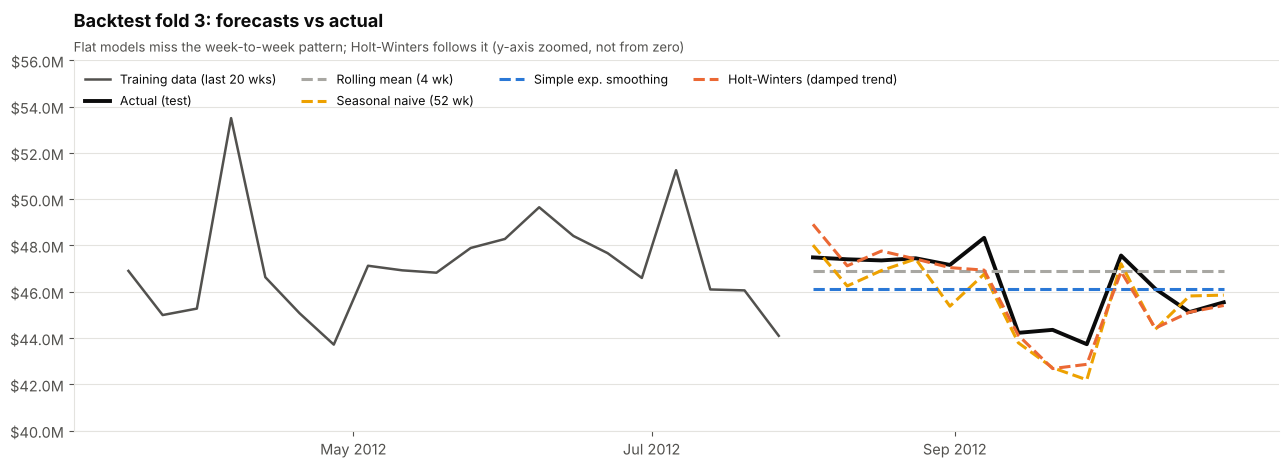

In [27]:
# What the forecasts looked like in the most recent fold (Aug–Oct 2012)
fold = 3
train_w, test_w = weekly.iloc[:FOLD_STARTS[-1]], weekly.iloc[FOLD_STARTS[-1]:FOLD_STARTS[-1] + H]
show = {"Rolling mean (4 wk)": OTHER, "Seasonal naive (52 wk)": YELLOW,
        "Simple exp. smoothing": BLUE, "Holt-Winters (damped trend)": ORANGE}

fig, ax = plt.subplots(figsize=(13, 4.8))
hist = train_w.iloc[-20:]
ax.plot(hist.index, hist.values, color=INK2, lw=1.8, label="Training data (last 20 wks)")
ax.plot(test_w.index, test_w.values, color=INK, lw=2.8, label="Actual (test)")
for name, c in show.items():
    p = fold_preds[(fold, name)]
    ax.plot(p.index, p.values, color=c, lw=2.2, ls="--", label=name)
ax.yaxis.set_major_formatter(MONEY); date_axis(ax, months=(3, 5, 7, 9)); ax.set_ylim(40e6, 56e6)
title(ax, "Backtest fold 3: forecasts vs actual", "Flat models miss the week-to-week pattern; Holt-Winters follows it (y-axis zoomed, not from zero)")
ax.legend(loc="upper left", ncol=4, fontsize=9)
plt.tight_layout(); plt.show()

### 11.1 Final forecast
The best-scoring model class (Holt-Winters) is refitted on **all** 143 weeks and projects the next **26 weeks** (Nov 2012 – Apr 2013). The shaded band is an 80% prediction interval from 1,000 bootstrap-simulated paths.

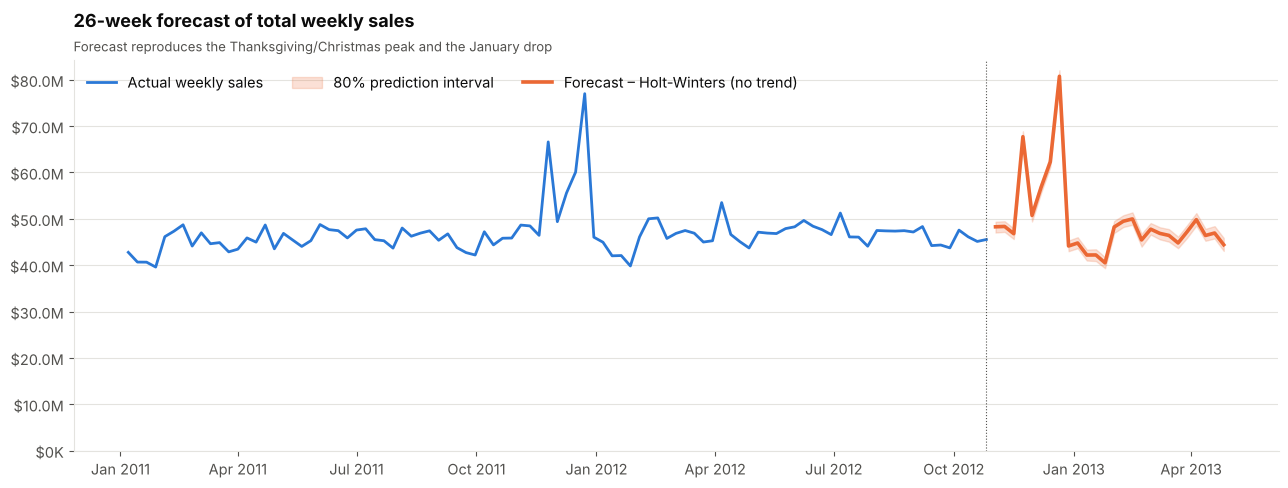

,weeks,avg_weekly_forecast,80% low,80% high
2012-11-01,5,$52.4M,$51.2M,$53.5M
2012-12-01,4,$61.0M,$59.8M,$62.2M
2013-01-01,4,$42.4M,$41.2M,$43.6M
2013-02-01,4,$48.3M,$47.0M,$49.6M
2013-03-01,5,$46.6M,$45.4M,$48.0M
2013-04-01,4,$46.9M,$45.7M,$48.3M


In [28]:
best_name = score.index[0]
assert "Holt-Winters" in best_name, f"Best model is {best_name}; adapt the final-forecast cell."
trend_arg, damped_arg = ("add", True) if "damped" in best_name else (None, False)

H_FINAL = 26
final_fit = ExponentialSmoothing(weekly, trend=trend_arg, damped_trend=damped_arg, seasonal="mul",
                                 seasonal_periods=52, initialization_method="estimated").fit()
fc = final_fit.forecast(H_FINAL)

sims = final_fit.simulate(H_FINAL, repetitions=1000, anchor="end", random_errors="bootstrap")
sims.index = fc.index
lo, hi = sims.quantile(0.10, axis=1), sims.quantile(0.90, axis=1)

fig, ax = plt.subplots(figsize=(13, 5))
hist = weekly.loc["2011-01-01":]
ax.plot(hist.index, hist.values, color=BLUE, lw=2, label="Actual weekly sales")
ax.fill_between(fc.index, lo, hi, color=ORANGE, alpha=0.2, label="80% prediction interval")
ax.plot(fc.index, fc.values, color=ORANGE, lw=2.6, label=f"Forecast – {best_name}")
ax.axvline(weekly.index[-1], color=INK2, lw=0.8, ls=":")
ax.yaxis.set_major_formatter(MONEY); date_axis(ax, months=(1, 4, 7, 10)); ax.set_ylim(0)
title(ax, "26-week forecast of total weekly sales",
      "Forecast reproduces the Thanksgiving/Christmas peak and the January drop")
ax.legend(loc="upper left", ncol=3)
plt.tight_layout(); plt.show()

fc_month = (pd.DataFrame({"forecast": fc, "lo": lo, "hi": hi})
              .groupby(pd.Grouper(freq="MS")).agg(weeks=("forecast", "size"), avg_weekly_forecast=("forecast", "mean"),
                                                  lo=("lo", "mean"), hi=("hi", "mean")))
fc_month.assign(**{c: fc_month[c].map(money) for c in ["avg_weekly_forecast", "lo", "hi"]}) \
        .rename(columns={"lo": "80% low", "hi": "80% high"})

**How to read the forecast**
- The shape (Nov–Dec peak, January trough) comes from seasonality that has been observed only **twice** in the data, so the year-end estimates deserve more caution than the spring ones. The bootstrap interval reflects historical in-sample noise only and probably **understates** true uncertainty at the holiday peak.
- Treat this as a baseline. A production forecast would add holiday/markdown/promotion regressors, forecast at store × department level, and be re-validated as new weeks arrive.

## 12. Summary, limitations & next steps

### Key findings
1. **Trend: essentially flat.** Average weekly sales in the like-for-like Feb–Oct window were \$46.1M (2010), \$45.8M (2011, −0.6%) and \$47.0M (2012, +2.5%). The 52-week average rose only ~1.9% over 1.7 years, and the STL trend strength is just 0.19.
2. **Seasonality dominates.** STL seasonal strength is 0.94. December runs ~25% above a typical week (index 1.25), November ~10% above, and January is the weakest month (0.89).
3. **The biggest week is not a flagged holiday.** The week before Christmas was the peak in both years (24 Dec 2010: \$80.9M, +73% vs trend; 23 Dec 2011: \$77.0M, +62%) but is not flagged `IsHoliday`. Flagged Thanksgiving weeks lift sales ~41%, whereas the flagged Christmas week (after Christmas) is ~8% *below* trend; Super Bowl (+3%) and Labor Day (−1%) are negligible.
4. **Product.** Revenue is broad-based: the top 5 departments make up 29% of sales and the top 10 make up 46%. Departments have distinct seasonal fingerprints — Dept 72 sells ~1.9× its normal rate in November and ~1.5× in December, and ~25% *less* than normal in summer. In Feb–Oct 2012 vs 2011, Depts 9 (+7.4%) and 92 (+7.1%) grew fastest; Dept 5 (−3.4%) and Dept 72 (−2.1%) declined.
5. **Region (store type).** Type A (22 stores) generates 64% of revenue, B (17 stores) 30% and C (6 stores) 6%. Per square foot the order reverses: C earns \$11.66 per week versus \$8.13 (B) and \$7.77 (A). All formats share the same seasonal shape (type B swings the most at year-end), and the best store (20) sells ~8× the weakest (33).
6. **Forecasting.** In a 3-fold rolling-origin backtest, Holt-Winters (multiplicative yearly seasonality) reached ~2.5% MAPE, versus 3.1% for seasonal naive, 5.1–5.2% for rolling means, 4.9% for simple exponential smoothing and 9.2% for naive. Trend-free and damped-trend variants tie, consistent with the flat trend. The 26-week forecast projects ~\$61M average weekly sales in December 2012 (vs ~\$57.6M in Dec 2011).

### Limitations
- **No true geography.** "Region" = store format (A/B/C) and individual stores; a real regional analysis needs location data.
- **Anonymised departments**, and department assortments change over time, so department growth mixes demand with assortment effects.
- **Short history** (~2.75 years): seasonal patterns rest on 2–3 observations per week-of-year; year-end behaviour in 2012 is unobserved (data stops in October).
- Weekly sales are aggregated across stores, so store-level anomalies are averaged out.

### Possible next steps
- Add `features.csv` drivers (temperature, fuel price, CPI, unemployment, markdowns) as regressors (e.g. SARIMAX / gradient boosting).
- Forecast at store × department level and reconcile to the total.
- Model holiday-week shifts explicitly (Thanksgiving/Christmas move relative to the calendar week).